<a href="https://colab.research.google.com/github/widyy123/Deforestation_Classification_Study_Case/blob/main/Deforestation_Classification_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1. SAMPEL DATASET SATELIT (5 BARIS PERTAMA) ===
   Radar_VV (S1)  Radar_VH (S1)  Optic_SWIR (S2)  Optic_NIR (S2)  \
0     -11.403943     -18.207396         0.282384        0.526151   
1     -12.280964     -15.631181         0.288372        0.426526   
2     -12.556101     -18.698595         0.262098        0.354336   
3     -12.674745     -19.519247         0.265712        0.404599   
4     -10.241221     -18.338664         0.253376        0.378763   

   Slope (SRTM)      Driver_Class  
0      4.531693  Smallholder Agri  
1      6.085120  Smallholder Agri  
2      1.550164  Smallholder Agri  
3      2.175393  Smallholder Agri  
4      3.911235  Smallholder Agri  

Jumlah Sampel per Kelas:
Driver_Class
Smallholder Agri     200
Mining               200
Road Development     200
Selective Logging    200
Name: count, dtype: int64

=== 2. MEMULAI PELATIHAN MODEL DEEP LEARNING ===
Model selesai dilatih!

AKURASI MODEL AKHIR (TEST SET) : 94.17%
MACRO F1-SCORE                : 0.9416

=== 

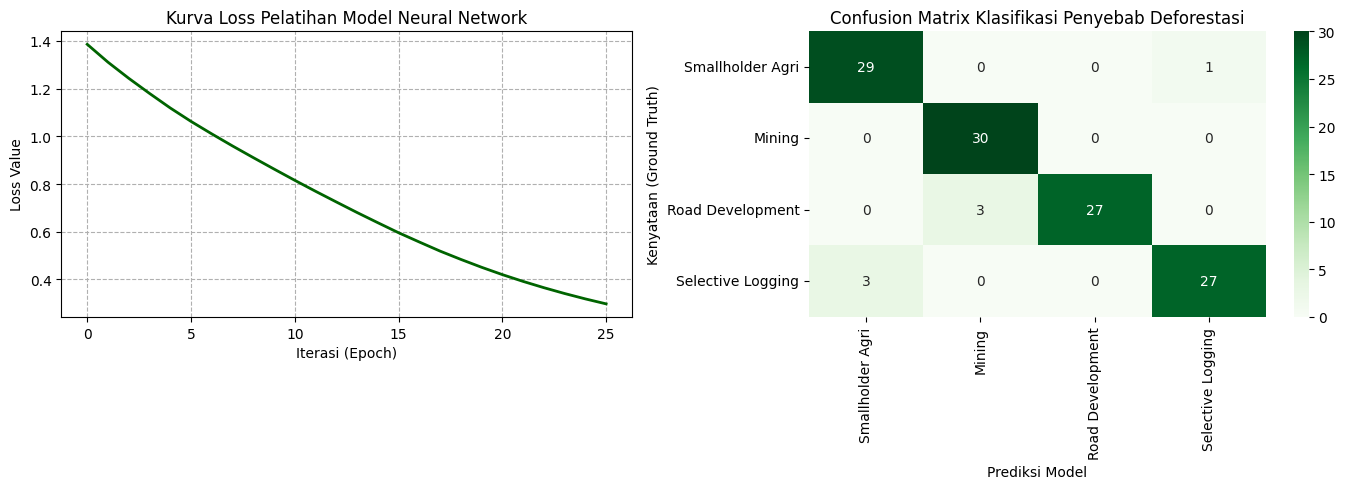

In [2]:
# ==============================================================================
# TUGAS UTS: STUDI KASUS KLASIFIKASI PENDORONG UTAMA DEFORESTASI (AI & SATELIT)
# Referensi: Bart Slagter et al. (Wageningen University & Research)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# ------------------------------------------------------------------------------
# STEP 1: PENGUMPULAN & SIMULASI DATASET SATELIT (SENTINEL-1 & SENTINEL-2)
# ------------------------------------------------------------------------------
# Fitur Spektral Satelit:
# 1. Radar_VV : Backscatter Sentinel-1 Polarisasi VV (dB)
# 2. Radar_VH : Backscatter Sentinel-1 Polarisasi VH (dB)
# 3. Optic_SWIR: Short-Wave Infrared Sentinel-2 (Banda 11/12)
# 4. Optic_NIR : Near Infrared Sentinel-2 (Banda 8)
# 5. Slope     : Kemiringan Topografi Lahan (Derajat)

np.random.seed(42)
n_samples_per_class = 200

# Class 0: Smallholder Agriculture (Pertanian Skala Kecil)
agri = np.random.normal(loc=[-12.0, -18.0, 0.25, 0.45, 5.0], scale=[1.2, 1.5, 0.05, 0.05, 2.0], size=(n_samples_per_class, 5))

# Class 1: Mining (Pertambangan)
mining = np.random.normal(loc=[-5.0, -10.0, 0.55, 0.12, 8.0], scale=[1.0, 1.2, 0.06, 0.04, 3.0], size=(n_samples_per_class, 5))

# Class 2: Road Development (Pembangunan Jalan)
road = np.random.normal(loc=[-8.5, -14.0, 0.35, 0.22, 3.0], scale=[1.1, 1.3, 0.04, 0.04, 1.5], size=(n_samples_per_class, 5))

# Class 3: Selective Logging (Penebangan Terpilih)
logging = np.random.normal(loc=[-14.0, -20.0, 0.20, 0.60, 12.0], scale=[1.0, 1.1, 0.03, 0.05, 4.0], size=(n_samples_per_class, 5))

# Penggabungan Dataset
X = np.vstack((agri, mining, road, logging))
y = np.array([0]*n_samples_per_class + [1]*n_samples_per_class + [2]*n_samples_per_class + [3]*n_samples_per_class)

class_names = ['Smallholder Agri', 'Mining', 'Road Development', 'Selective Logging']
feature_names = ['Radar_VV (S1)', 'Radar_VH (S1)', 'Optic_SWIR (S2)', 'Optic_NIR (S2)', 'Slope (SRTM)']

df = pd.DataFrame(X, columns=feature_names)
df['Driver_Class'] = [class_names[i] for i in y]

print("=== 1. SAMPEL DATASET SATELIT (5 BARIS PERTAMA) ===")
print(df.head())
print("\nJumlah Sampel per Kelas:")
print(df['Driver_Class'].value_counts())

# ------------------------------------------------------------------------------
# STEP 2: PREPROCESSING DATA & DIVISION
# ------------------------------------------------------------------------------
# Split Train (70%), Validation (15%), Test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Standarisasi Skala Fitur (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------------------
# STEP 3: PEMBANGUNAN & PELATIHAN MODEL NEURAL NETWORK (DEEP LEARNING ARCHITECTURE)
# ------------------------------------------------------------------------------
# Arsitektur MLP Classifier (Deep Neural Network)
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32), # 2 Hidden Layers
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42,
    early_stopping=True
)

print("\n=== 2. MEMULAI PELATIHAN MODEL DEEP LEARNING ===")
mlp.fit(X_train_scaled, y_train)
print("Model selesai dilatih!")

# ------------------------------------------------------------------------------
# STEP 4: EVALUASI MODEL & METRIK KINERJA
# ------------------------------------------------------------------------------
y_pred = mlp.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"\n==================================================")
print(f"AKURASI MODEL AKHIR (TEST SET) : {acc * 100:.2f}%")
print(f"MACRO F1-SCORE                : {macro_f1:.4f}")
print(f"==================================================\n")

print("=== LAPORAN EVALUASI DETAIL (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred, target_names=class_names))

# ------------------------------------------------------------------------------
# STEP 5: VISUALISASI HASIL (CONFUSION MATRIX & HISTORI LOSS)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss Curve Pelatihan
axes[0].plot(mlp.loss_curve_, color='darkgreen', linewidth=2)
axes[0].set_title('Kurva Loss Pelatihan Model Neural Network')
axes[0].set_xlabel('Iterasi (Epoch)')
axes[0].set_ylabel('Loss Value')
axes[0].grid(True, linestyle='--')

# Plot 2: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix Klasifikasi Penyebab Deforestasi')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Kenyataan (Ground Truth)')

plt.tight_layout()
plt.show()